# STA 4155: codigo y resultados paso a paso

Cada celda contiene codigo real del archivo **todo_el_codigo_comentado.py**. Las tablas y los graficos debajo se producen al ejecutar ese codigo desde los CSV originales. No se cargan fotos de resultados anteriores.

Lee los comentarios en espanol. Puedes ejecutar una celda con **Shift+Enter** o usar **Run All** para ejecutar todo en orden. Los resultados guardados permiten revisar el ejemplo sin ejecutarlo de nuevo.

El informe para entregar es un documento separado: revisen el formato del PDF, expliquen las decisiones con sus palabras e incluyan las contribuciones del grupo.

In [1]:
# STA 4155 - TODO EL CODIGO JUNTO, CON EXPLICACIONES EN ESPANOL
# Este archivo es una copia completa y ejecutable del ejemplo.
# No necesitas ejecutar analysis.py antes: aqui se cargan los CSV y se calcula todo.
# Cada marca # %% separa una etapa. VS Code puede mostrarlas como celdas.
# El notebook proyecto_paso_a_paso.ipynb usa exactamente estas mismas celdas.
# Para ejecutarlo como archivo desde la carpeta principal:
# python "chat version/todo_el_codigo_comentado.py"
# Los numeros se calculan; las imagenes son graficos creados por Matplotlib.

from pathlib import Path
import sys
import platform
import importlib.metadata

# Localizar la carpeta que contiene los CSV, tanto en .py como en notebook.
base = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
ROOT = next((p for p in [base, *base.parents]
             if (p / "Fires.csv").is_file() and (p / "Salaries.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Abre el proyecto desde la carpeta sta4155 project")

# Las bibliotecas locales de esta computadora se prepararon para Python 3.14.
# Otros interpretes deben instalar requirements-notebook.txt en su propio entorno.
local_packages = ROOT / ".packages"
if sys.version_info[:2] == (3, 14) and local_packages.exists():
    sys.path.insert(0, str(local_packages))

# pandas maneja tablas; NumPy calcula; statsmodels ajusta las regresiones;
# scipy aporta pruebas estadisticas y Matplotlib dibuja los graficos.
import numpy as np
import pandas as pd
import matplotlib
# En el notebook mostramos las figuras debajo del codigo.
# Como script guardamos las mismas figuras en results, sin abrir ventanas.
try:
    EN_NOTEBOOK = get_ipython().__class__.__name__ == "ZMQInteractiveShell"
except NameError:
    EN_NOTEBOOK = False
if EN_NOTEBOOK:
    get_ipython().run_line_magic("matplotlib", "inline")
else:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import shapiro

OUT = ROOT / "chat version" / "results"
OUT.mkdir(exist_ok=True)
report = ["# STA 4155: worked Python example", "Observational associations do not establish causation. Alpha = 0.05. Intervals assume the fitted model is appropriate."]

# Esta funcion muestra tablas en notebook y texto legible al ejecutar el .py.
def mostrar_tabla(tabla):
    if EN_NOTEBOOK:
        from IPython.display import display
        display(tabla)
    else:
        print(tabla.to_string())


def mostrar_figura(fig):
    # La figura se crea con datos y comandos de Python, no leyendo un PNG previo.
    if EN_NOTEBOOK:
        from IPython.display import display
        display(fig)
    plt.close(fig)


In [2]:
# 1. FUNCION COMPARTIDA PARA LOS MODELOS
# OLS = minimos cuadrados ordinarios: estima los coeficientes que minimizan
# la suma de residuos al cuadrado. La formula indica respuesta ~ predictores.
# Un residuo es el valor observado menos el valor estimado por el modelo.
def analyze(name, data, formula):
    model = smf.ols(formula, data=data, missing="raise").fit()
    (OUT / f"{name}_summary.txt").write_text(model.summary().as_text(), encoding="utf-8")
    # summary() muestra coeficientes, errores estandar, pruebas t, F y R cuadrado.
    # H0 global: todas las pendientes (excepto el intercepto) son cero.
    # Cada prueba t contrasta H0: el coeficiente correspondiente es cero.
    print("\nMODELO:", name, "|", formula)
    print(model.summary())
    # Los intervalos que siguen son los clasicos OLS (suponen varianza constante).
    ci = model.conf_int()
    pd.DataFrame({"estimate": model.params, "SE": model.bse, "p": model.pvalues,
                  "CI_low": ci[0], "CI_high": ci[1]}).to_csv(OUT / f"{name}_coefficients.csv")
    mostrar_tabla(pd.DataFrame({"coef_OLS": model.params,
        "SE_clasico": model.bse, "p_clasico": model.pvalues,
        "IC95_inferior": ci[0], "IC95_superior": ci[1]}))
    # Leverage: posicion inusual de los predictores. Cook: influencia en el ajuste.
    # 4/n es una regla de revision, no una orden de borrar observaciones.
    infl = model.get_influence()
    pd.DataFrame({"row": data.index + 1, "residual": model.resid,
                  "leverage": infl.hat_matrix_diag, "Cooks_D": infl.cooks_distance[0]}).to_csv(OUT / f"{name}_influence.csv", index=False)
    mostrar_tabla(pd.DataFrame({"fila_CSV_sin_encabezado": data.index + 1,
        "residuo": model.resid, "leverage": infl.hat_matrix_diag,
        "Cook_D": infl.cooks_distance[0]}).sort_values("Cook_D", ascending=False).head())
    # BP: H0 = varianza constante. Shapiro: H0 = residuos normales.
    # p < 0.05 aporta evidencia contra H0; p grande no demuestra el supuesto.
    bp = het_breuschpagan(model.resid, model.model.exog)
    sw = shapiro(model.resid)
    mostrar_tabla(pd.DataFrame({"prueba": ["Breusch-Pagan LM", "Shapiro-Wilk"],
        "estadistico": [bp[0], sw.statistic], "p_valor": [bp[1], sw.pvalue]}))
    # Izquierda: buscar curvatura o forma de embudo. Centro: revisar la Q-Q.
    # Derecha: buscar observaciones influyentes. La independencia depende del muestreo.
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    ax[0].scatter(model.fittedvalues, model.resid)
    ax[0].axhline(0, color="red")
    ax[0].set(xlabel="Fitted", ylabel="Residual", title="Residuals vs fitted")
    sm.qqplot(model.resid, line="s", ax=ax[1])
    ax[2].stem(data.index + 1, infl.cooks_distance[0])
    ax[2].axhline(4/len(data), color="red", linestyle="--")
    ax[2].set(xlabel="Row", ylabel="Cook's D", title="Influence (4/n screening line)")
    fig.tight_layout(); fig.savefig(OUT / f"{name}_diagnostics.png", dpi=160); mostrar_figura(fig)
    report.extend([f"## {name}", f"Formula: `{formula}`. n={int(model.nobs)}; R²={model.rsquared:.4f}; adjusted R²={model.rsquared_adj:.4f}; overall F-test p={model.f_pvalue:.5g}.",
        f"Breusch-Pagan LM p={bp[1]:.5g}; Shapiro-Wilk p={sw.pvalue:.5g}. Small p-values flag possible violations; large p-values do not prove assumptions. Independence depends on sampling design and cannot be established by these tests.",
        f"![Diagnostics]({name}_diagnostics.png)", f"See {name}_summary.txt and coefficient/influence CSV files. Points above 4/n need review, not automatic deletion."])
    # HC3 estima errores estandar robustos a varianza desigual.
    # No cambia las pendientes OLS: cambia su incertidumbre, pruebas e intervalos.
    # No soluciona por si solo una mala forma funcional o falta de independencia.
    robust = model.get_robustcov_results(cov_type="HC3")
    robust_ci = robust.conf_int()
    mostrar_tabla(pd.DataFrame({"coef_OLS": model.params,
        "SE_clasico": model.bse, "p_clasico": model.pvalues,
        "SE_HC3": robust.bse, "p_HC3": robust.pvalues,
        "IC95_HC3_inf": robust_ci[:, 0], "IC95_HC3_sup": robust_ci[:, 1]}))
    (OUT / f"{name}_HC3.txt").write_text(robust.summary().as_text(), encoding="utf-8")
    report.append("Overall hypothesis: all non-intercept slopes equal zero. " + ("Reject at 5%; the model provides evidence of association." if model.f_pvalue < .05 else "Do not reject at 5%; evidence of association is insufficient."))
    report.append("Diagnostic interpretation: " + ("the constant-variance assumption is questioned by the BP test; compare the HC3 output." if bp[1] < .05 else "the BP test does not detect unequal variance at 5%.") + (" The Q-Q plot needs particular attention because Shapiro-Wilk rejects normality." if sw.pvalue < .05 else " Shapiro-Wilk does not reject normality at 5%."))
    return model


In [3]:
# 2. CARGAR Y REVISAR LOS DATOS ORIGINALES
# read_csv lee los datos. No se modifica ninguno de los tres archivos originales.
# En Salaries, Y YA es log(salario): no hay que aplicarle otro logaritmo.
fires = pd.read_csv(ROOT / "Fires.csv")
salary = pd.read_csv(ROOT / "Salaries.csv")
for label, df in [("fires", fires), ("salaries", salary)]:
    print("\nDATOS:", label, "| filas:", len(df))
    mostrar_tabla(df.head())
    print("Valores faltantes por columna:")
    mostrar_tabla(df.isna().sum().to_frame("faltantes"))
    print("Estadisticas descriptivas:")
    mostrar_tabla(df.describe())
    df.describe().to_csv(OUT / f"{label}_descriptive.csv")
    df.isna().sum().to_csv(OUT / f"{label}_missing.csv")
    if df.isna().any().any():
        raise ValueError(f"Missing data in {label}: decide how to handle before fitting")



DATOS: fires | filas: 15


,DISTANCE,DAMAGE
0,3.4,26.2
1,1.8,17.8
2,4.6,31.3
3,2.3,23.1
4,3.1,27.5


Valores faltantes por columna:


,faltantes
DISTANCE,0
DAMAGE,0


Estadisticas descriptivas:


,DISTANCE,DAMAGE
count,15.000000,15.000000
mean,3.280000,26.413333
std,1.576252,8.068976
min,0.700000,14.100000
25%,2.200000,20.950000
50%,3.100000,26.100000
75%,4.450000,31.300000
max,6.100000,43.200000


... (2 outputs left out)

Valores faltantes por columna:


,faltantes
ID,0
Y,0
X1,0
X2,0
X3,0
X4,0
X5,0
X6,0
X7,0
X8,0


Estadisticas descriptivas:


,ID,Y,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,100.00000
mean,50.500000,11.455018,13.080000,16.020000,0.660000,340.100000,175.10000,0.490000,42.840000,7.700000,0.180000,24.83000
std,29.011492,0.259811,7.342529,2.304935,0.476095,167.177973,15.40661,0.502418,9.072903,1.553751,0.386123,2.74158
min,1.000000,10.664300,1.000000,12.000000,0.000000,60.000000,150.00000,0.000000,23.000000,5.000000,0.000000,20.00000
25%,25.750000,11.281975,7.750000,14.000000,0.000000,187.500000,160.00000,0.000000,37.000000,6.000000,0.000000,23.00000
50%,50.500000,11.462700,13.000000,16.000000,1.000000,360.000000,180.00000,0.000000,42.500000,8.000000,0.000000,25.00000
75%,75.250000,11.608000,20.000000,18.000000,1.000000,492.500000,190.00000,1.000000,49.250000,9.000000,0.000000,27.00000
max,100.000000,12.063400,26.000000,20.000000,1.000000,600.000000,200.00000,1.000000,64.000000,10.000000,1.000000,30.00000



MODELO: fires | DAMAGE ~ DISTANCE
                            OLS Regression Results                            
Dep. Variable:                 DAMAGE   R-squared:                       0.923
Model:                            OLS   Adj. R-squared:                  0.918
Method:                 Least Squares   F-statistic:                     156.9
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           1.25e-08
Time:                        18:37:32   Log-Likelihood:                -32.811
No. Observations:                  15   AIC:                             69.62
Df Residuals:                      13   BIC:                             71.04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     10.

,coef_OLS,SE_clasico,p_clasico,IC95_inferior,IC95_superior
Intercept,10.277929,1.420278,6.585564e-06,7.209605,13.346252
DISTANCE,4.919331,0.392748,1.247800e-08,4.070851,5.767811


,fila_CSV_sin_encabezado,residuo,leverage,Cook_D
12,13,2.914154,0.295289,0.470558
10,11,3.391477,0.106697,0.143316
8,9,-3.468188,0.079960,0.105884
13,14,2.509284,0.133088,0.103909
11,12,1.610808,0.203293,0.077442


,prueba,estadistico,p_valor
0,Breusch-Pagan LM,0.182134,0.669546
1,Shapiro-Wilk,0.946715,0.474276


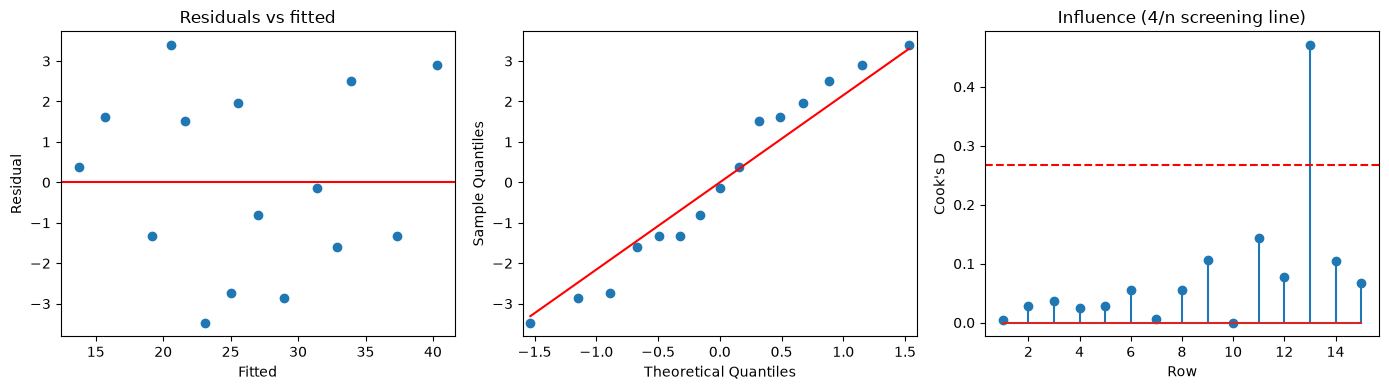

,coef_OLS,SE_clasico,p_clasico,SE_HC3,p_HC3,IC95_HC3_inf,IC95_HC3_sup
Intercept,10.277929,1.420278,6.585564e-06,1.451064,8.255825e-06,7.143095,13.412762
DISTANCE,4.919331,0.392748,1.247800e-08,0.439928,4.849942e-08,3.968924,5.869737


In [4]:
# 3. INCENDIOS: REGRESION LINEAL SIMPLE
# Respuesta: DAMAGE (miles de dolares). Predictor: DISTANCE (millas).
# Pendiente: cambio promedio del dano por una milla adicional.
# R cuadrado: proporcion de variacion del dano explicada dentro de esta muestra.
# No demuestra que distancia cause dano: estos datos son observacionales.
fire = analyze("fires", fires, "DAMAGE ~ DISTANCE")


,DISTANCE,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,0.700000,13.721460,1.176628,11.179511,16.263409,8.108694,19.334226
24,2.009091,20.161311,0.779002,18.478379,21.844244,14.881738,25.440885
49,3.372727,26.869489,0.599186,25.575027,28.163952,21.700615,32.038364
74,4.736364,33.577668,0.827564,31.789824,35.365511,28.263722,38.891613
99,6.100000,40.285846,1.258714,37.566559,43.005133,34.590571,45.981121


Ecuacion estimada: DAMAGE = 10.2779 + 4.9193 * DISTANCE


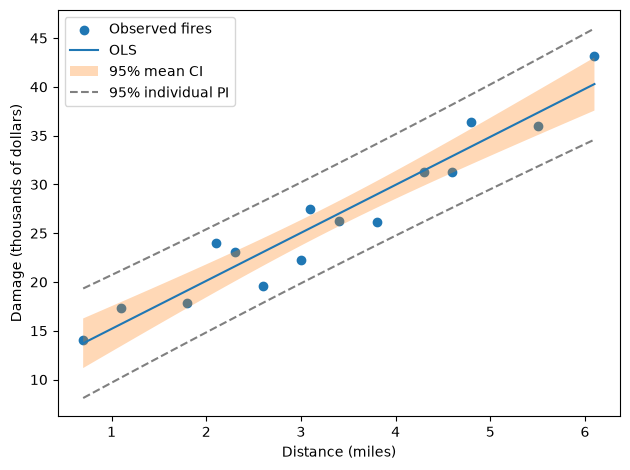

In [5]:
# 4. INCENDIOS: PREDICCIONES Y GRAFICO CREADO DESDE CERO
# Solo usamos distancias dentro del rango observado para evitar extrapolar.
# IC de la media: incertidumbre sobre dano promedio a cierta distancia.
# Intervalo de prediccion: incertidumbre sobre un incendio individual (mas ancho).
grid = pd.DataFrame({"DISTANCE": np.linspace(fires.DISTANCE.min(), fires.DISTANCE.max(), 100)})
pred = fire.get_prediction(grid).summary_frame()
pd.concat([grid, pred], axis=1).to_csv(OUT / "fires_predictions.csv", index=False)
mostrar_tabla(pd.concat([grid, pred], axis=1).iloc[[0, 24, 49, 74, 99]])
print(f"Ecuacion estimada: DAMAGE = {fire.params.iloc[0]:.4f} + {fire.params.iloc[1]:.4f} * DISTANCE")
fig, ax = plt.subplots()
ax.scatter(fires.DISTANCE, fires.DAMAGE, label="Observed fires")
ax.plot(grid.DISTANCE, pred["mean"], label="OLS")
ax.fill_between(grid.DISTANCE, pred.mean_ci_lower, pred.mean_ci_upper, alpha=.3, label="95% mean CI")
ax.plot(grid.DISTANCE, pred.obs_ci_lower, "--", color="gray", label="95% individual PI")
ax.plot(grid.DISTANCE, pred.obs_ci_upper, "--", color="gray")
ax.set(xlabel="Distance (miles)", ylabel="Damage (thousands of dollars)")
ax.legend(); fig.tight_layout(); fig.savefig(OUT / "fires_fit.png", dpi=160); mostrar_figura(fig)
report.extend([f"Estimated damage = {fire.params.iloc[0]:.4f} + {fire.params.iloc[1]:.4f} × distance. One additional mile is associated with {fire.params.iloc[1]:.4f} thousand dollars more damage on average. Slope p={fire.pvalues.iloc[1]:.5g}. The intercept may have little practical meaning if zero miles is outside the data range.", "![Fire model](fires_fit.png)", "Mean confidence bands estimate average damage; wider prediction bands describe one new fire. Avoid extrapolation."])



MODELO: salaries_full | Y ~ X1 + X2 + X3 + X4 + X5 + X6 + X7 + X8 + X9 + X10
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.923
Model:                            OLS   Adj. R-squared:                  0.914
Method:                 Least Squares   F-statistic:                     106.5
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           4.41e-45
Time:                        18:37:34   Log-Likelihood:                 121.52
No. Observations:                 100   AIC:                            -221.0
Df Residuals:                      89   BIC:                            -192.4
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------

,coef_OLS,SE_clasico,p_clasico,IC95_inferior,IC95_superior
Intercept,10.021921,0.148052,2.445252e-78,9.727745,10.316096
X1,0.027921,0.001773,1.837246e-27,0.024398,0.031445
X2,0.029033,0.003426,4.567812e-13,0.022227,0.035840
X3,0.224336,0.017079,1.521429e-22,0.190400,0.258272
X4,0.000514,0.000049,3.908977e-17,0.000416,0.000612
X5,0.002048,0.000525,1.855990e-04,0.001005,0.003091
X6,-0.015377,0.016857,3.641243e-01,-0.048871,0.018117
X7,-0.000510,0.001438,7.237948e-01,-0.003367,0.002347
X8,-0.002633,0.005128,6.088957e-01,-0.012823,0.007557
X9,-0.026560,0.020369,1.956126e-01,-0.067033,0.013913


,fila_CSV_sin_encabezado,residuo,leverage,Cook_D
39,40,-0.201770,0.137185,0.117816
90,91,-0.152853,0.129001,0.062392
95,96,0.160196,0.116700,0.060281
14,15,0.122774,0.151743,0.049921
46,47,0.185952,0.071817,0.045267


,prueba,estadistico,p_valor
0,Breusch-Pagan LM,20.301281,0.026528
1,Shapiro-Wilk,0.993306,0.905791


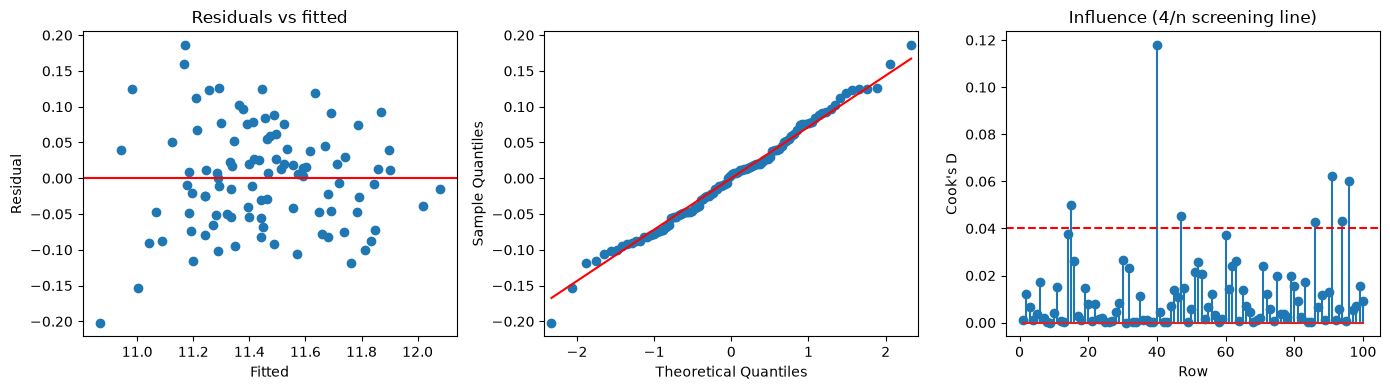

,coef_OLS,SE_clasico,p_clasico,SE_HC3,p_HC3,IC95_HC3_inf,IC95_HC3_sup
Intercept,10.021921,0.148052,2.445252e-78,0.196845,1.321649e-67,9.630793,10.413048
X1,0.027921,0.001773,1.837246e-27,0.001805,5.924512e-27,0.024334,0.031508
X2,0.029033,0.003426,4.567812e-13,0.003912,6.590817e-11,0.021259,0.036807
X3,0.224336,0.017079,1.521429e-22,0.020454,3.287379e-18,0.183694,0.264977
X4,0.000514,0.000049,3.908977e-17,0.000054,3.237235e-15,0.000407,0.000621
X5,0.002048,0.000525,1.855990e-04,0.000562,4.521043e-04,0.000931,0.003165
X6,-0.015377,0.016857,3.641243e-01,0.017609,3.848858e-01,-0.050366,0.019612
X7,-0.000510,0.001438,7.237948e-01,0.001559,7.444741e-01,-0.003607,0.002588
X8,-0.002633,0.005128,6.088957e-01,0.004959,5.967434e-01,-0.012487,0.007220
X9,-0.026560,0.020369,1.956126e-01,0.020066,1.890199e-01,-0.066431,0.013311


In [6]:
# 5. SALARIOS: MODELO MULTIPLE COMPLETO
# ID es un identificador, no un predictor. Y ya esta en logaritmo natural.
# X1 experiencia, X2 educacion, X3 bono (0/1), X4 empleados supervisados,
# X5 activos (millones), X6 junta (0/1), X7 edad, X8 ganancias (millones),
# X9 responsabilidad internacional (0/1), X10 ventas (millones).
# Cada pendiente se interpreta manteniendo constantes los otros predictores.
predictors = [f"X{i}" for i in range(1,11)]
full = analyze("salaries_full", salary, "Y ~ " + " + ".join(predictors))


In [7]:
# 6. COLINEALIDAD ENTRE PREDICTORES
# VIF mide inflacion de la varianza de un coeficiente por relaciones entre X.
# Un VIF alto invita a investigar; ningun corte sustituye el criterio del curso.
X = full.model.exog
pd.DataFrame({"variable": full.model.exog_names[1:], "VIF": [variance_inflation_factor(X,i) for i in range(1,X.shape[1])]}).to_csv(OUT / "salaries_VIF.csv", index=False)
mostrar_tabla(pd.read_csv(OUT / "salaries_VIF.csv"))


,variable,VIF
0,X1,2.899350
1,X2,1.066207
2,X3,1.130768
3,X4,1.157739
4,X5,1.118820
5,X6,1.226695
6,X7,2.910214
7,X8,1.085804
8,X9,1.057876
9,X10,1.125675


,paso,quitada,AIC
0,0,ninguna,-221.049019
1,1,X10,-222.926517
2,2,X7,-224.829533
3,3,X8,-226.544761
4,4,X6,-227.905567
5,5,X9,-228.139058



MODELO: salaries_exploratory_AIC | Y ~ X1 + X2 + X3 + X4 + X5
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.921
Model:                            OLS   Adj. R-squared:                  0.916
Method:                 Least Squares   F-statistic:                     218.1
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           4.30e-50
Time:                        18:37:35   Log-Likelihood:                 120.07
No. Observations:                 100   AIC:                            -228.1
Df Residuals:                      94   BIC:                            -212.5
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------

,coef_OLS,SE_clasico,p_clasico,IC95_inferior,IC95_superior
Intercept,9.961935,0.101057,1.100504e-96,9.761284,10.162585
X1,0.027276,0.001029,2.127412e-45,0.025233,0.029320
X2,0.029092,0.003337,9.714998e-14,0.022467,0.035717
X3,0.224693,0.016350,3.260363e-24,0.192229,0.257157
X4,0.000524,0.000047,1.029513e-18,0.000430,0.000619
X5,0.001962,0.000497,1.526953e-04,0.000975,0.002949


,fila_CSV_sin_encabezado,residuo,leverage,Cook_D
39,40,-0.201219,0.098309,0.144603
95,96,0.169031,0.072597,0.071232
90,91,-0.147154,0.089477,0.069030
85,86,-0.134403,0.099909,0.065798
93,94,0.141608,0.089825,0.064222


,prueba,estadistico,p_valor
0,Breusch-Pagan LM,25.610623,0.000106
1,Shapiro-Wilk,0.993845,0.933397


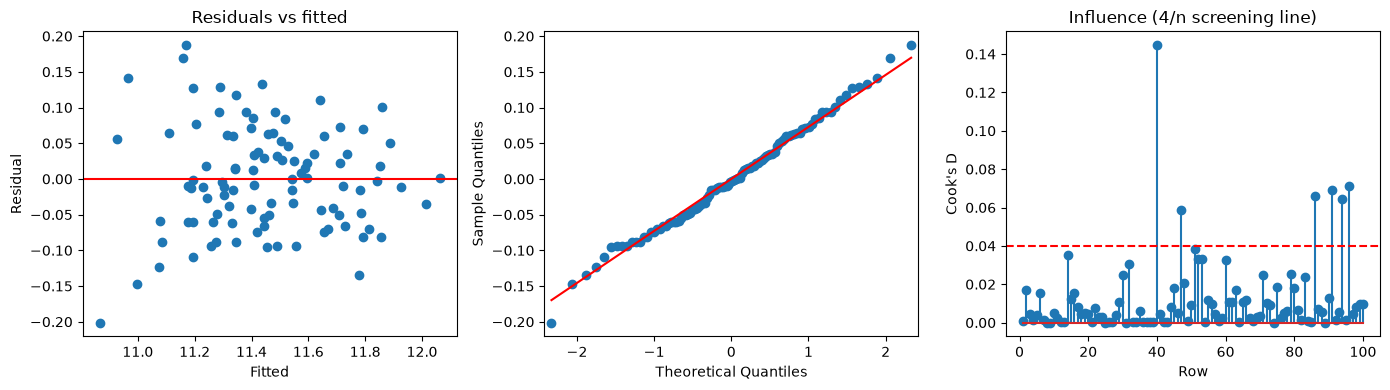

,coef_OLS,SE_clasico,p_clasico,SE_HC3,p_HC3,IC95_HC3_inf,IC95_HC3_sup
Intercept,9.961935,0.101057,1.100504e-96,0.132001,6.466034e-86,9.699843,10.224026
X1,0.027276,0.001029,2.127412e-45,0.001048,9.490920e-45,0.025195,0.029357
X2,0.029092,0.003337,9.714998e-14,0.003813,1.888928e-11,0.021522,0.036662
X3,0.224693,0.016350,3.260363e-24,0.020177,7.275080e-19,0.184631,0.264755
X4,0.000524,0.000047,1.029513e-18,0.000050,2.072657e-17,0.000425,0.000624
X5,0.001962,0.000497,1.526953e-04,0.000537,4.257992e-04,0.000896,0.003029


,modelo,predictores,R2,R2_ajustado,AIC
0,completo,10,0.922905,0.914242,-221.049019
1,AIC exploratorio,5,0.920628,0.916407,-228.139058


In [8]:
# 7. REDUCCION EXPLORATORIA POR AIC
# Se prueba quitar una variable cada vez y se conserva el cambio si reduce AIC.
# Menor AIC favorece balance ajuste-complejidad; no garantiza mejor prediccion.
# El modelo completo sigue siendo la referencia. La seleccion usa la misma muestra:
# p-valores e intervalos posteriores no incorporan la incertidumbre de seleccionar.
# Si necesitan evaluar prediccion, hay que usar validacion fuera de esta muestra.
aic_history = [{"paso": 0, "quitada": "ninguna", "AIC": full.aic}]
selected = predictors.copy()
current = full
while len(selected) > 1:
    trials = [(smf.ols("Y ~ " + " + ".join(x for x in selected if x != drop), salary).fit(), drop) for drop in selected]
    candidate, drop = min(trials, key=lambda pair: pair[0].aic)
    if candidate.aic >= current.aic - 1e-8: break
    selected.remove(drop); current = candidate
    aic_history.append({"paso": len(aic_history), "quitada": drop, "AIC": current.aic})
mostrar_tabla(pd.DataFrame(aic_history))
reduced = analyze("salaries_exploratory_AIC", salary, "Y ~ " + " + ".join(selected))
mostrar_tabla(pd.DataFrame({"modelo": ["completo", "AIC exploratorio"],
    "predictores": [len(predictors), len(selected)],
    "R2": [full.rsquared, reduced.rsquared],
    "R2_ajustado": [full.rsquared_adj, reduced.rsquared_adj],
    "AIC": [full.aic, reduced.aic]}))


In [9]:
# 8. INTERPRETAR COEFICIENTES EN ESCALA DE SALARIO
# 100*(exp(b)-1) convierte un coeficiente logaritmico en cambio porcentual.
# Para una variable binaria, corresponde pasar de 0 a 1, con el resto constante.
# Aqui usamos HC3 porque BP detecta varianza desigual en salarios.
# La interpretacion como mediana supone mediana condicional cero del error log.
# No confundir exp(prediccion log) con salario medio: existe sesgo de transformacion.
hc3 = full.get_robustcov_results(cov_type="HC3")
hc3_ci = hc3.conf_int()
mostrar_tabla(pd.DataFrame({"variable": full.params.index[1:],
    "cambio_porcentual": 100 * np.expm1(full.params.iloc[1:].to_numpy()),
    "IC95_HC3_inf_pct": 100 * np.expm1(hc3_ci[1:, 0]),
    "IC95_HC3_sup_pct": 100 * np.expm1(hc3_ci[1:, 1]),
    "p_HC3": hc3.pvalues[1:]}))


,variable,cambio_porcentual,IC95_HC3_inf_pct,IC95_HC3_sup_pct,p_HC3
0,X1,2.831449,2.463242,3.200979,5.924512e-27
1,X2,2.945873,2.148693,3.749274,6.590817e-11
2,X3,25.149099,20.164857,30.340079,3.287379e-18
3,X4,0.051410,0.040671,0.062150,3.237235e-15
4,X5,0.205014,0.093150,0.317004,4.521043e-04
5,X6,-1.525939,-4.911892,1.980583,3.848858e-01
6,X7,-0.050958,-0.360088,0.259131,7.444741e-01
7,X8,-0.262974,-1.240896,0.724631,5.967434e-01
8,X9,-2.621045,-6.427281,1.340016,1.890199e-01
9,X10,-0.097694,-0.675394,0.483366,7.385041e-01


In [10]:
# 9. GUARDAR EL INFORME AUTOMATICO Y LAS SALIDAS PARA CONSULTARLAS
# El informe original conserva sus intervalos clasicos OLS como referencia.
# Para salarios, comparar con las tablas HC3 mostradas arriba y los archivos HC3.txt.
# Las frases contienen numeros formateados desde los modelos, no resultados escritos a mano.
report.extend(["## Salary interpretation", "Y already contains natural log salary: do not log it again. ID is an identifier, excluded from predictors. X3, X6, X9 are binary indicators. Other coefficients adjust for all included predictors.",
    f"Full AIC={full.aic:.3f}; exploratory reduced AIC={reduced.aic:.3f}. Selected predictors: {', '.join(selected)}. Selection and evaluation use the same sample: reduced-model p-values and intervals ignore selection uncertainty. AIC improvement is not evidence of out-of-sample accuracy.",
    "For each coefficient b, 100*(exp(b)-1) gives the modeled percentage change in median salary for a one-unit increase (or 0-to-1 indicator change), holding other variables fixed. Exponentiating a log prediction estimates median salary, not automatically mean salary. Currency units are not specified in the supplied variable table."])
for term in full.params.index[1:]:
    lo, hi = full.conf_int().loc[term]
    report.append(f"- {term}: adjusted median salary change {100*np.expm1(full.params[term]):.2f}%; 95% CI [{100*np.expm1(lo):.2f}%, {100*np.expm1(hi):.2f}%]; p={full.pvalues[term]:.5g}.")
report.extend(["## Review before writing your own report", "Inspect residual shape, spread, Q-Q departures, VIF and influential cases. Consider robust HC3 standard errors if variance is unequal; they do not fix model misspecification. Check variable relevance and possible nonlinearities against course methods. Neither dataset supports a causal claim without additional design evidence.", "Include your research questions, methods, numerical findings, limitations, relevant computer output, and group contributions. This example does not supply member names or invent contribution percentages."])
(OUT / "REPORT.md").write_text("\n\n".join(report), encoding="utf-8")
print(f"Results saved to {OUT}")


Results saved to C:\Users\mauri\.codex\.chatgpt-projects\g-p-67bf55837f648191a30723c97317f4e8\sta4155 project\chat version\results


In [11]:
# 10. REGISTRAR VERSIONES PARA FACILITAR LA REPRODUCCION
# Si otro equipo obtiene un error, comparen estas versiones y su interprete.
versions = {"Python": platform.python_version()}
for package in ["pandas", "numpy", "scipy", "statsmodels", "matplotlib"]:
    versions[package] = importlib.metadata.version(package)
mostrar_tabla(pd.Series(versions, name="version").to_frame())
(OUT / "versiones_ejemplo.txt").write_text(
    "\n".join(f"{k}=={v}" for k, v in versions.items()), encoding="utf-8")
print("Listo: todos los calculos anteriores salieron del codigo y de los CSV.")


,version
Python,3.14.4
pandas,3.1.1
numpy,2.5.4
scipy,1.18.1
statsmodels,0.15.0
matplotlib,3.11.2


Listo: todos los calculos anteriores salieron del codigo y de los CSV.
